# Gender Demographics & FAIR Data Sharing (2011-2025)

This notebook analyses the relationship between **author gender** and
data-sharing behaviour across 15 years of PubMed Central publications,
centred on the 2016 FAIR principles paper by Wilkinson et al.

**Gender is inferred from given names** using a two-strategy pipeline:
1. `names_dataset` -- global name-gender probability database (primary)
2. `gender_guesser` -- rule-based fallback for European name traditions

Names producing a clear signal (>=80% one gender) are classified as
`female` or `male`. Genuinely ambiguous names (*Kim*, *Andrea*, *Wei*)
and bare initials are kept as `ambiguous`/`unknown` and **excluded from
binary comparisons** to avoid systematic misclassification.

> **Methodological note**: name-based gender inference is a proxy. It
> conflates gender identity with name-pattern expectations, has lower
> reliability for East Asian and African names, and cannot capture
> non-binary identities. All findings should be read with caution.

---

| Section | Topic |
|---------|-------|
| 0 | Setup, DB connection, gender-inference engine |
| 1 | Corpus gender composition over time |
| 2 | data-sharing score gap: female vs male first authors |
| 3 | Pre vs post-2016 gap change + bootstrap DiD |
| 4 | DAS category composition by gender |
| 5 | Gender x Discipline (Stage 6) |
| 6 | Gender x Funder (Stage 6) |
| 7 | Gender x Open Access (Stage 6) |
| 8 | Productivity trajectories by gender |
| 9 | International collaboration x gender |
| 10 | Inference quality audit |
| 11 | Statistical summary dashboard + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'pycountry']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## 0 . Setup

In [2]:
import sqlite3, warnings, importlib
import matplotlib; importlib.reload(matplotlib)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
importlib.reload(matplotlib)
plt = matplotlib.pyplot

# Style
sns.set_theme(style='whitegrid', font_scale=1.15)
PALETTE    = sns.color_palette('tab10')
FAIR_YEAR  = 2016
FIG_W, FIG_H = 13, 5
G_PAL = {'female': '#e377c2', 'male': '#1f77b4', 'ambiguous': '#bcbd22'}

# Database
DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row
con.execute("PRAGMA cache_size = -1000000")  # ~1GB page cache for this connection, instead of SQLite's 2MB default

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

# Detect available tables
tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}
HAS_DISC   = 'article_discipline' in tables
HAS_FUNDER = 'article_funder'     in tables
HAS_OA     = 'journal_oa'         in tables
HAS_AFFIL  = 'affiliation'        in tables
print('Tables detected:', len(tables))
print(f'  Discipline (Stage 6): {chr(9989) if HAS_DISC   else chr(9888)}')
print(f'  Funder     (Stage 6): {chr(9989) if HAS_FUNDER else chr(9888)}')
print(f'  OA status  (Stage 6): {chr(9989) if HAS_OA     else chr(9888)}')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


Tables detected: 33
  Discipline (Stage 6): ✅
  Funder     (Stage 6): ✅
  OA status  (Stage 6): ✅


### Gender inference engine

In [3]:
# Gender is no longer inferred live inside this notebook. names_dataset and
# gender_guesser (loaded here previously) held ~2-4GB in the same kernel as
# this notebook's own DataFrames, which was the direct cause of past OOM
# kernel deaths -- see the note in the next cell for the full story. Gender
# inference now runs offline, once, via:
#
#     python pipeline/compute_gender.py --db data/processed/pmc_fair.db
#
# which writes one row per distinct author.given_name to a new
# `given_name_gender(given_name, gender, inference_score, source)` table
# using the exact same inference logic (names_dataset -> gender_guesser
# fallback, 0.80 threshold) that used to run live here. Every query below
# now just LEFT JOINs against that table instead of calling any model.
#
# METHODOLOGICAL CAVEAT (see review/chatgpt_review_gender.md): this is
# NAME-BASED GENDER INFERENCE, not a measurement of author gender identity.
# It does not use country/affiliation context, cannot identify non-binary
# authors, and has not been validated against ground truth for this
# corpus -- treat every result in this notebook as an exploratory
# secondary signal, and see the paper's limitations section before citing
# any number derived from it as a finding about "author gender".
_HAS_GENDER_TABLE = 'given_name_gender' in tables
assert _HAS_GENDER_TABLE, (
    "given_name_gender table not found -- run "
    "`python pipeline/compute_gender.py --db data/processed/pmc_fair.db` first."
)

_gender_dist = qdb("SELECT gender, COUNT(*) AS n FROM given_name_gender GROUP BY gender ORDER BY n DESC")
_source_dist = qdb("SELECT source, COUNT(*) AS n FROM given_name_gender GROUP BY source ORDER BY n DESC")
print('given_name_gender table found.')
print('\nDistribution over distinct given names, by inferred label:')
print(_gender_dist.to_string(index=False))
print('\nDistribution by inference source (how much relies on the less-reliable fallback):')
print(_source_dist.to_string(index=False))

given_name_gender table found.

Distribution over distinct given names, by inferred label:
   gender      n
     male 675564
  unknown 625752
   female 616709
ambiguous 232810

Distribution by inference source (how much relies on the less-reliable fallback):
        source       n
 names_dataset 1498508
       unknown  625752
gender_guesser   26575


---
## 1 . Corpus Gender Composition Over Time

**First author** (position=1) is the primary unit here; senior/last-author
analysis follows in section 5. We expect a gradual rise in female
representation driven by workforce trends, independent of FAIR.


In [4]:
# Pull FIRST-AUTHOR records only, directly filtered in SQL, with gender
# resolved via a LEFT JOIN against the precomputed given_name_gender table
# (see the cell above) rather than classified live in this kernel.
#
# An earlier version of this cell (named `df_raw`) pulled every article_author
# row -- all author positions, not just first authors, ~47.25M rows -- into a
# 7-column pandas frame and kept it alive for the rest of the notebook. That
# frame alone measured ~7.7GB even after converting to category dtype, and it
# also forced the join to be planned without the `author_position = 1` filter,
# so SQLite could not use the efficient article(year)->article_author(article_id)
# index path and instead did a much slower, near-full scan of a 27GB database.
# Combined with the ~2-4GB names_dataset held once it was instantiated live in
# this kernel, plus every DataFrame/figure built up over the rest of the
# notebook's run, this is what was killing the kernel (OOM) -- and,
# independently, made the cell itself take minutes just to run the query.
# Gender inference has since moved out of this kernel entirely (see the cell
# above), which removes that ~2-4GB model footprint regardless.
#
# Only ONE thing in the whole notebook (the "All authors" comparison in the
# Statistical Summary section, far below) actually needs non-first-author
# rows. That comparison is now computed separately, streamed in memory-bounded
# chunks, right where it's used -- see that cell for details. Everything else
# here only ever needed first-author rows, so we query exactly that (and get
# a much faster, index-driven query as a side effect: article filtered by
# year, then a direct article_id lookup into article_author, instead of a
# near-full scan of all 47M rows).
df_first = qdb("""
    SELECT aa.article_id,
           aa.author_position,
           a.year  AS year,
           dc.data_sharing_score,
           dc.primary_category      AS cat,
           au.given_name,
           au.author_id,
           COALESCE(gg.gender, 'unknown')         AS gender,
           COALESCE(gg.inference_score, 0.0)      AS g_conf
    FROM article_author  aa
    JOIN article          a   ON a.article_id  = aa.article_id
    JOIN das_category     dc  ON dc.article_id = aa.article_id
    JOIN author            au  ON au.author_id  = aa.author_id
    LEFT JOIN given_name_gender gg ON gg.given_name = au.given_name
    WHERE aa.author_position = 1 AND a.year BETWEEN 2011 AND 2025
""")

df_first['period']  = df_first['year'].apply(
    lambda y: 'pre' if y < FAIR_YEAR else ('fair_yr' if y == FAIR_YEAR else 'post'))

print('Gender distribution (all first authors):')
print(df_first['gender'].value_counts().to_string())
resolved = df_first['gender'].isin(['female','male']).mean()
print(f'\nResolution rate (F+M): {resolved*100:.1f}%')

Gender distribution (all first authors):
gender
male         2672411
female       2143536
ambiguous    1200859
unknown       813536



Resolution rate (F+M): 70.5%


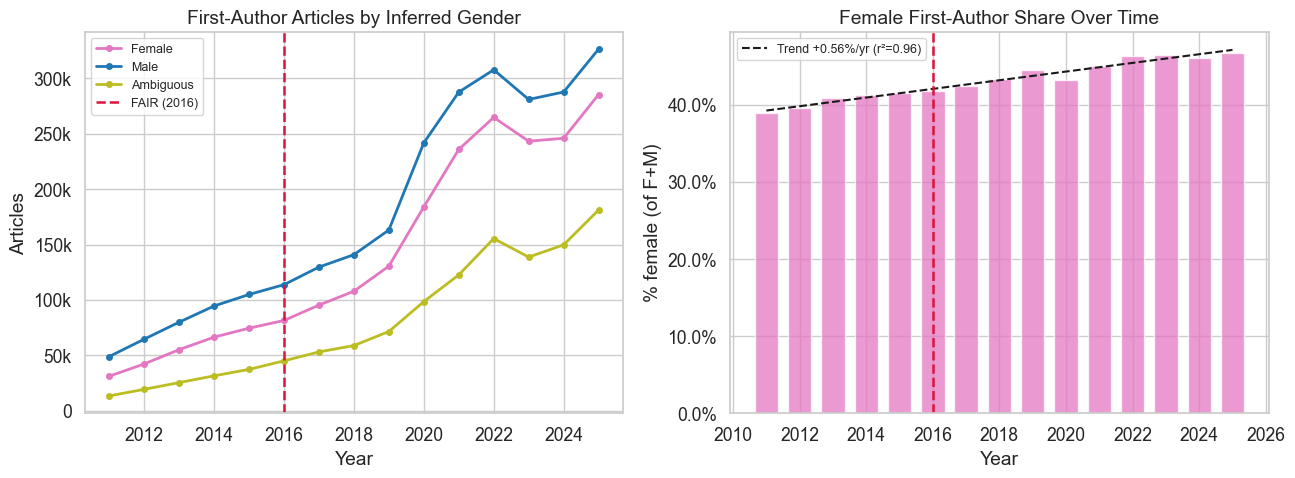

Pre-FAIR  mean % female: 40.4%
Post-FAIR mean % female: 44.9%


In [5]:
# Composition over time
comp = (df_first.groupby(['year','gender'])
        .size().reset_index(name='n'))
comp_piv = (comp.pivot_table(index='year', columns='gender', values='n', aggfunc='sum')
            .fillna(0))
for g in ['female','male','ambiguous','unknown']:
    if g not in comp_piv.columns: comp_piv[g] = 0

denom = comp_piv[['female','male']].sum(axis=1)
pct_f = comp_piv['female'] / denom * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
for g, c in [('female','#e377c2'),('male','#1f77b4'),('ambiguous','#bcbd22')]:
    ax.plot(comp_piv.index, comp_piv[g], lw=2, marker='o', ms=4, color=c, label=g.capitalize())
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--', label='FAIR (2016)')
ax.set_title('First-Author Articles by Inferred Gender')
ax.set_xlabel('Year'); ax.set_ylabel('Articles')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{int(x/1e3)}k' if x>=1000 else str(int(x))))
ax.legend(fontsize=9)

ax = axes[1]
ax.bar(pct_f.index, pct_f.values, color='#e377c2', alpha=0.75, edgecolor='white', width=0.7)
slope, intercept, r, p_tr, _ = stats.linregress(pct_f.dropna().index, pct_f.dropna().values)
xs = np.array(pct_f.index)
ax.plot(xs, intercept + slope*xs, 'k--', lw=1.5, label=f'Trend {slope:+.2f}%/yr (r²={r**2:.2f})')
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Female First-Author Share Over Time')
ax.set_xlabel('Year'); ax.set_ylabel('% female (of F+M)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_g01_composition.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Pre-FAIR  mean % female: {pct_f[pct_f.index < FAIR_YEAR].mean():.1f}%')
print(f'Post-FAIR mean % female: {pct_f[pct_f.index > FAIR_YEAR].mean():.1f}%')


---
## 2 . Data-Sharing Score Gap -- Female vs Male First Authors

Do female-led papers share data at higher or lower rates?
Prior bibliometric work is mixed: some studies find women publish
more in open-access venues; field-composition effects are a major
confound (addressed in section 6).


In [ ]:
df_fm = df_first[df_first['gender'].isin(['female','male'])].copy()

score_stats = (df_fm.groupby('gender')['data_sharing_score']
               .agg(n='count', mean='mean', median='median', std='std')
               .reset_index())
score_stats['se']   = score_stats['std'] / np.sqrt(score_stats['n'])
score_stats['ci95'] = 1.96 * score_stats['se']

f_sc = df_fm[df_fm['gender']=='female']['data_sharing_score']
m_sc = df_fm[df_fm['gender']=='male'  ]['data_sharing_score']
u_stat, p_val = stats.mannwhitneyu(f_sc, m_sc, alternative='two-sided')
# u_stat / (n1*n2) is the common-language effect size (CLES, probability a
# random female-authored article outscores a random male-authored one),
# NOT the rank-biserial correlation r -- CLES=0.5 is the null point, so
# applying Cohen's-d-style thresholds (<0.1 negligible ... >0.5 large)
# directly to CLES silently mislabels a near-null effect as 'medium' or
# larger. True rank-biserial r = 2*CLES - 1 (0 = no effect, +-1 = complete
# separation); that is what the thresholds below are calibrated for.
cles  = u_stat / (len(f_sc) * len(m_sc))
r_eff = 2 * cles - 1

print('data-sharing score by first-author gender:')
print(score_stats[['gender','n','mean','median','std','ci95']].round(3).to_string(index=False))
print(f'\nMann-Whitney U={u_stat:.0f}, p={p_val:.3e}')
print(f'Effect size r={r_eff:.4f}  (< 0.1 negligible | 0.1-0.3 small | 0.3-0.5 medium | >0.5 large)')


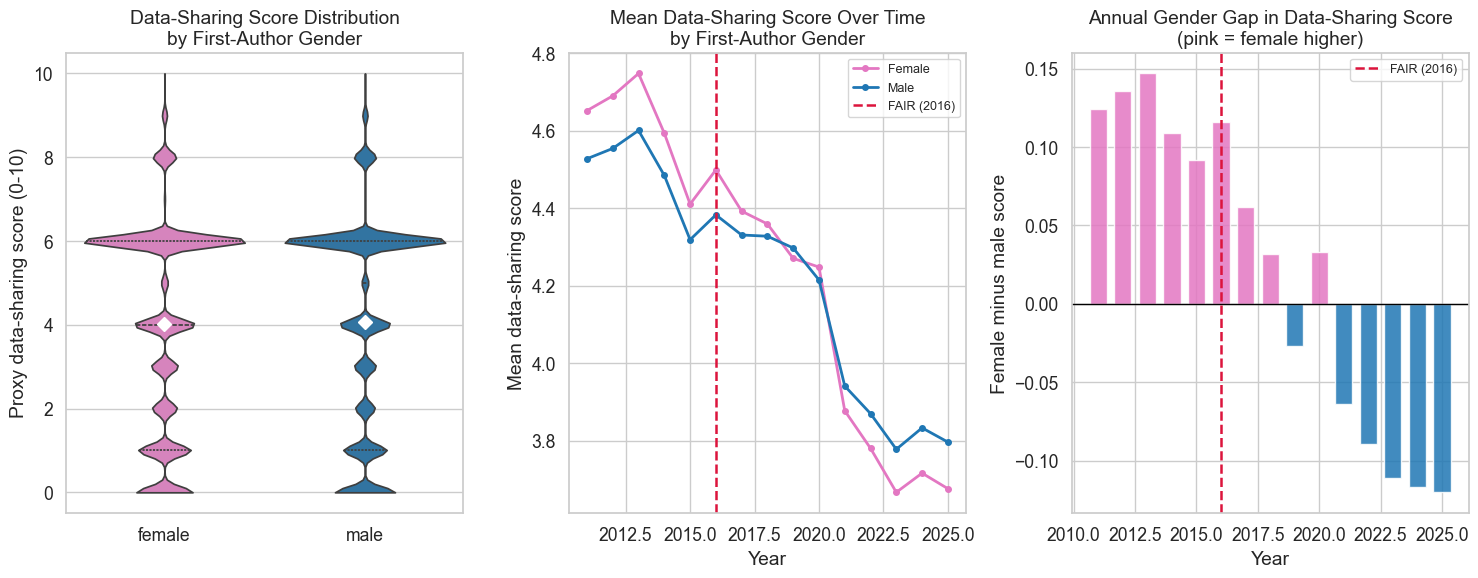

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# Violin
ax = axes[0]
sns.violinplot(data=df_fm, x='gender', y='data_sharing_score',
               palette=G_PAL, inner='quartile', ax=ax, cut=0)
for i, row in score_stats.iterrows():
    ax.errorbar(i, row['mean'], yerr=row['ci95'],
                fmt='D', color='white', ms=7, capsize=4, zorder=5)
ax.set_xlabel('')
ax.set_ylabel('Proxy data-sharing score (0-10)')
ax.set_title('Data-Sharing Score Distribution\nby First-Author Gender')

# Mean score per year
score_yr = (df_fm.groupby(['year','gender'])['data_sharing_score']
            .mean().reset_index())
ax = axes[1]
for g, c in [('female','#e377c2'),('male','#1f77b4')]:
    grp = score_yr[score_yr['gender']==g].sort_values('year')
    ax.plot(grp['year'], grp['data_sharing_score'], lw=2, marker='o', ms=4,
            color=c, label=g.capitalize())
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--', label='FAIR (2016)')
ax.set_xlabel('Year'); ax.set_ylabel('Mean data-sharing score')
ax.set_title('Mean Data-Sharing Score Over Time\nby First-Author Gender')
ax.legend(fontsize=9)

# Annual gap (female - male)
gap_yr = (score_yr.pivot_table(index='year', columns='gender', values='data_sharing_score')
          .assign(gap=lambda d: d['female'] - d['male']))
ax = axes[2]
ax.bar(gap_yr.index, gap_yr['gap'],
       color=['#e377c2' if v >= 0 else '#1f77b4' for v in gap_yr['gap']],
       alpha=0.85, edgecolor='white', width=0.7)
ax.axhline(0, color='black', lw=1)
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--', label='FAIR (2016)')
ax.set_xlabel('Year'); ax.set_ylabel('Female minus male score')
ax.set_title('Annual Gender Gap in Data-Sharing Score\n(pink = female higher)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_g02_fair_gap.png", **SAVEFIG_KWARGS)
plt.show()


---
## 3 . Did the Gender Gap Change After 2016?

If female researchers were already more open-data oriented, the gap
might widen post-FAIR. If male-dominated fields adopted FAIR faster,
it could narrow. We use a **bootstrap difference-in-differences** to
test whether the improvement rates were equal across genders.


In [8]:
df_no16 = df_fm[df_fm['year'] != FAIR_YEAR].copy()

period_stats = (df_no16.groupby(['period','gender'])['data_sharing_score']
                .agg(n='count', mean='mean', std='std').reset_index())
period_stats['ci95'] = 1.96 * period_stats['std'] / np.sqrt(period_stats['n'])

f_pre  = df_no16[(df_no16['gender']=='female') & (df_no16['year']<FAIR_YEAR)]['data_sharing_score']
f_post = df_no16[(df_no16['gender']=='female') & (df_no16['year']>FAIR_YEAR)]['data_sharing_score']
m_pre  = df_no16[(df_no16['gender']=='male')   & (df_no16['year']<FAIR_YEAR)]['data_sharing_score']
m_post = df_no16[(df_no16['gender']=='male')   & (df_no16['year']>FAIR_YEAR)]['data_sharing_score']

f_delta = f_post.mean() - f_pre.mean()
m_delta = m_post.mean() - m_pre.mean()
did_obs = f_delta - m_delta

# Bootstrap DiD
rng = np.random.default_rng(42)
n_boot = 5000
boot = []
for _ in range(n_boot):
    fp = rng.choice(f_post.values, size=min(5000, len(f_post)), replace=True).mean()
    fr = rng.choice(f_pre.values,  size=min(5000, len(f_pre)),  replace=True).mean()
    mp = rng.choice(m_post.values, size=min(5000, len(m_post)), replace=True).mean()
    mr = rng.choice(m_pre.values,  size=min(5000, len(m_pre)),  replace=True).mean()
    boot.append((fp-fr)-(mp-mr))
boot = np.array(boot)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
p_boot = np.mean(boot <= 0) if did_obs > 0 else np.mean(boot >= 0)

print(f'Female improvement : {f_delta:+.3f}')
print(f'Male   improvement : {m_delta:+.3f}')
print(f'DiD (F-M)          : {did_obs:+.3f}')
print(f'Bootstrap 95% CI   : [{ci_lo:+.3f}, {ci_hi:+.3f}]')
print(f'Bootstrap p (1-sided): {p_boot:.4f}')


Female improvement : -0.693
Male   improvement : -0.501
DiD (F-M)          : -0.192
Bootstrap 95% CI   : [-0.335, -0.059]
Bootstrap p (1-sided): 0.0032


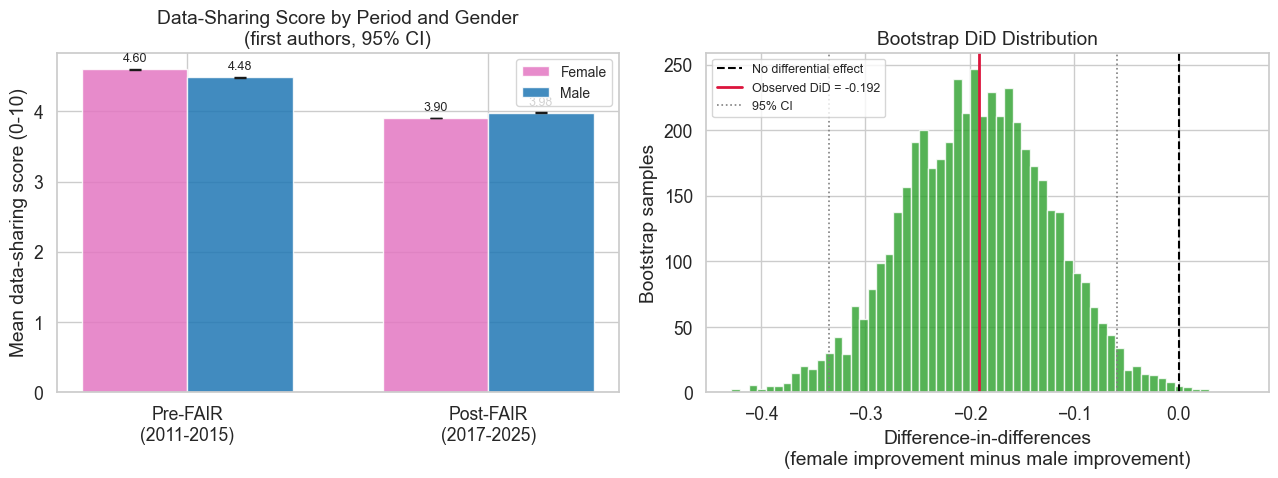

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

# Grouped bar pre/post
ax = axes[0]
periods = ['pre','post']
x = np.arange(2); w = 0.35
for j, (g, c) in enumerate([('female','#e377c2'),('male','#1f77b4')]):
    means = [period_stats[(period_stats['gender']==g) &
                          (period_stats['period']==p)]['mean'].values for p in periods]
    cis   = [period_stats[(period_stats['gender']==g) &
                          (period_stats['period']==p)]['ci95'].values for p in periods]
    mn = [v[0] if len(v) else np.nan for v in means]
    er = [v[0] if len(v) else 0      for v in cis]
    b  = ax.bar(x+(j-0.5)*w, mn, w, label=g.capitalize(),
                color=c, alpha=0.85, edgecolor='white', yerr=er, capsize=4)
    ax.bar_label(b, fmt='{:.2f}', padding=3, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Pre-FAIR\n(2011-2015)','Post-FAIR\n(2017-2025)'])
ax.set_ylabel('Mean data-sharing score (0-10)')
ax.set_title('Data-Sharing Score by Period and Gender\n(first authors, 95% CI)')
ax.legend(fontsize=10)

# Bootstrap DiD distribution
ax = axes[1]
ax.hist(boot, bins=60, color=PALETTE[2], alpha=0.8, edgecolor='white')
ax.axvline(0,       color='black',  lw=1.5, ls='--', label='No differential effect')
ax.axvline(did_obs, color='crimson', lw=2,            label=f'Observed DiD = {did_obs:+.3f}')
ax.axvline(ci_lo,   color='grey',   lw=1.2, ls=':')
ax.axvline(ci_hi,   color='grey',   lw=1.2, ls=':', label='95% CI')
ax.set_xlabel('Difference-in-differences\n(female improvement minus male improvement)')
ax.set_ylabel('Bootstrap samples')
ax.set_title('Bootstrap DiD Distribution')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_g03_did.png", **SAVEFIG_KWARGS)
plt.show()


---
## 4 . Data Availability Statement Categories by Gender

Beyond the scalar data-sharing score, does the *type* of data sharing differ?
For example, are female first authors more likely to name a specific
repository, while male authors more often write 'available on request'?
We test each category with a chi-squared proportion test.


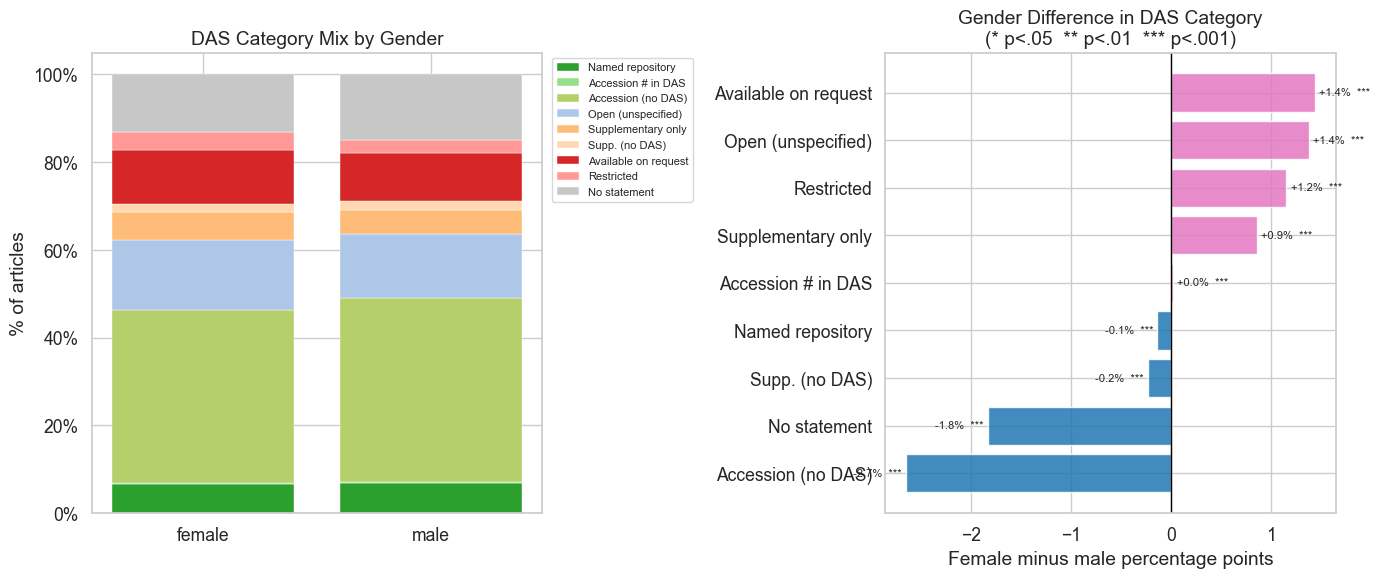

In [10]:
CAT_ORDER = [
    'repository_named','accession_provided','no_das_but_accession',
    'open_unspecified','supplementary_only','no_das_but_supp',
    'available_on_request','restricted','no_statement',
]
CAT_LABELS = {
    'repository_named':     'Named repository',
    'accession_provided':   'Accession # in DAS',
    'no_das_but_accession': 'Accession (no DAS)',
    'open_unspecified':     'Open (unspecified)',
    'supplementary_only':   'Supplementary only',
    'no_das_but_supp':      'Supp. (no DAS)',
    'available_on_request': 'Available on request',
    'restricted':           'Restricted',
    'no_statement':         'No statement',
}
CAT_COLOURS = {
    'repository_named':'#2ca02c','accession_provided':'#98df8a',
    'no_das_but_accession':'#b5cf6b','open_unspecified':'#aec7e8',
    'supplementary_only':'#ffbb78','no_das_but_supp':'#ffd8b1',
    'available_on_request':'#d62728','restricted':'#ff9896','no_statement':'#c7c7c7',
}

cat_g = (df_fm.groupby(['gender','cat'])['article_id']
         .count().reset_index(name='n'))
piv_cat = (cat_g.pivot_table(index='gender', columns='cat', values='n', aggfunc='sum')
           .fillna(0))
piv_cat = piv_cat.reindex([c for c in CAT_ORDER if c in piv_cat.columns], axis=1)
piv_pct = piv_cat.div(piv_cat.sum(axis=1), axis=0) * 100

# Chi-squared for each category
delta_rows = []
for cat in piv_pct.columns:
    fp = piv_pct.loc['female', cat] if 'female' in piv_pct.index else 0
    mp = piv_pct.loc['male',   cat] if 'male'   in piv_pct.index else 0
    fn = piv_cat.loc['female', cat] if 'female' in piv_cat.index else 0
    mn = piv_cat.loc['male',   cat] if 'male'   in piv_cat.index else 0
    ft = piv_cat.loc['female'].sum() if 'female' in piv_cat.index else 1
    mt = piv_cat.loc['male'].sum()   if 'male'   in piv_cat.index else 1
    try:
        _, p_chi, _, _ = stats.chi2_contingency([[fn, ft-fn],[mn, mt-mn]])
        sig = '***' if p_chi<0.001 else ('**' if p_chi<0.01 else ('*' if p_chi<0.05 else 'ns'))
    except Exception:
        sig = ''
    delta_rows.append({'cat':cat,'delta':fp-mp,'sig':sig,'f_pct':fp,'m_pct':mp})

df_delta = pd.DataFrame(delta_rows).sort_values('delta')

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 1, FIG_H + 1))

# Stacked bar
ax = axes[0]
bot = np.zeros(len(piv_pct))
for cat in piv_pct.columns:
    ax.bar(piv_pct.index, piv_pct[cat], bottom=bot,
           color=CAT_COLOURS.get(cat,'#aaa'), label=CAT_LABELS.get(cat,cat),
           edgecolor='white', lw=0.3)
    bot += piv_pct[cat].values
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Category Mix by Gender')
ax.set_ylabel('% of articles')
ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)

# Delta bar
ax = axes[1]
clrs = ['#e377c2' if d>0 else '#1f77b4' for d in df_delta['delta']]
bars = ax.barh([CAT_LABELS.get(c,c) for c in df_delta['cat']],
               df_delta['delta'], color=clrs, alpha=0.85, edgecolor='white')
ax.bar_label(bars,
             labels=[f'{d:+.1f}%  {s}' for d,s in zip(df_delta['delta'], df_delta['sig'])],
             padding=3, fontsize=8)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Female minus male percentage points')
ax.set_title('Gender Difference in DAS Category\n(* p<.05  ** p<.01  *** p<.001)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_g04_categories.png", **SAVEFIG_KWARGS)
plt.show()


---
## 5 . Gender x Discipline *(Stage 6)*

Field composition is a major confounder: if women are over-represented
in high-data-sharing fields (e.g. genomics), an apparent gender effect
may just be a discipline effect. This section decomposes the gap within
each discipline and checks whether female under-representation in a
field predicts a larger or smaller FAIR gap.


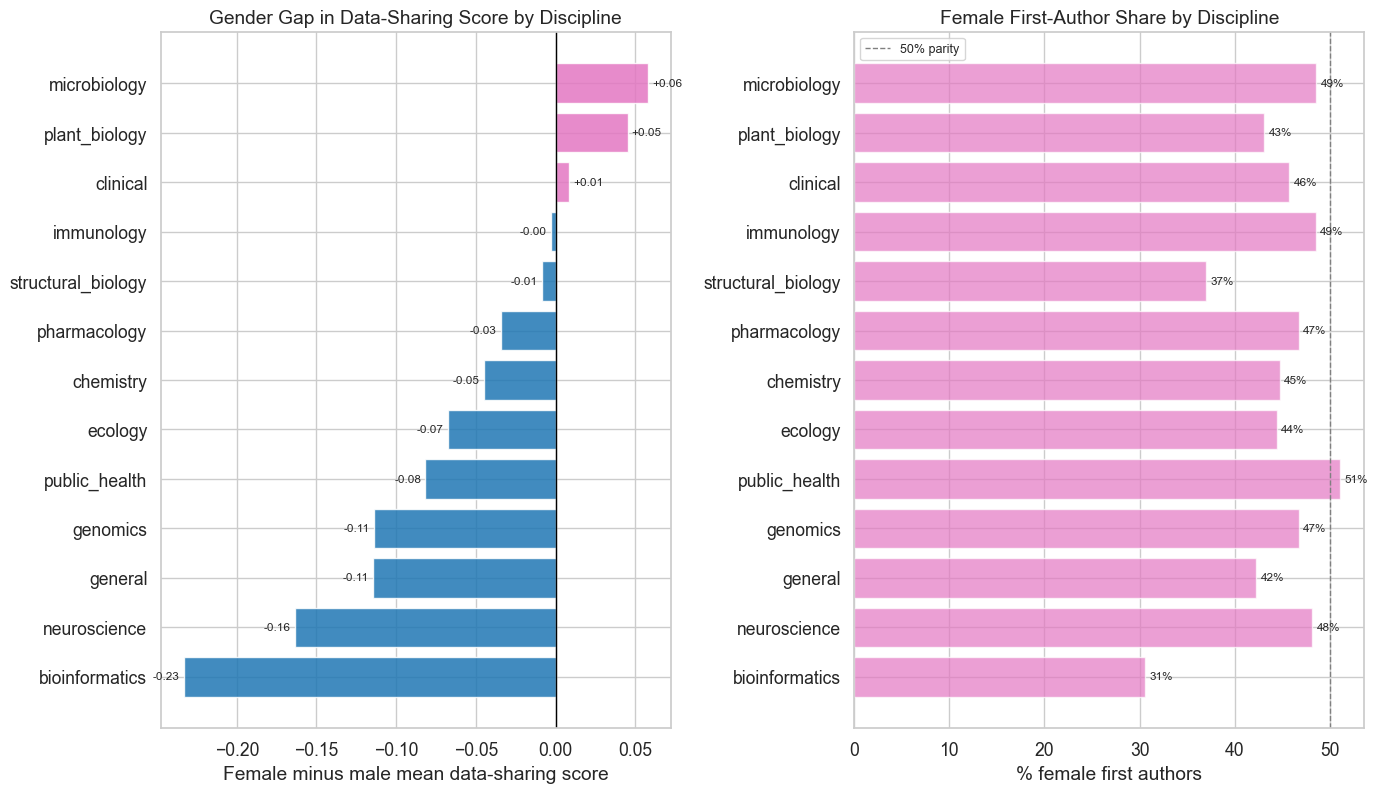

gender              female   male    gap
discipline                              
bioinformatics       4.563  4.796 -0.233
neuroscience         4.245  4.408 -0.163
general              3.635  3.749 -0.115
genomics             5.181  5.295 -0.114
public_health        3.512  3.593 -0.082
ecology              4.616  4.684 -0.068
chemistry            4.328  4.373 -0.045
pharmacology         4.291  4.325 -0.034
structural_biology   5.541  5.549 -0.009
immunology           4.218  4.220 -0.003
clinical             3.917  3.909  0.008
plant_biology        4.241  4.196  0.045
microbiology         4.449  4.391  0.058


In [11]:
if not HAS_DISC:
    print('Skipped -- discipline data not available in this database.')
else:
    df_dg = qdb("""
        SELECT aa.article_id, aa.author_position,
               a.year AS year,
               dc.data_sharing_score, au.given_name, ad.discipline,
               COALESCE(gg.gender, 'unknown') AS gender
        FROM article_author    aa
        JOIN article           a   ON a.article_id  = aa.article_id
        JOIN das_category      dc  ON dc.article_id = aa.article_id
        JOIN author            au  ON au.author_id  = aa.author_id
        JOIN article_discipline ad ON ad.article_id = aa.article_id
        LEFT JOIN given_name_gender gg ON gg.given_name = au.given_name
        WHERE aa.author_position = 1 AND a.year BETWEEN 2011 AND 2025
    """)
    df_dg = df_dg[df_dg['gender'].isin(['female','male'])]

    dg = (df_dg.groupby(['discipline','gender'])['data_sharing_score']
          .agg(n='count', mean='mean').reset_index())
    dg_piv = (dg[dg['n']>=20]
              .pivot_table(index='discipline',columns='gender',values='mean')
              .dropna())
    dg_piv['gap'] = dg_piv.get('female',0) - dg_piv.get('male',0)
    dg_piv = dg_piv.sort_values('gap')

    disc_share = (df_dg.groupby(['discipline','gender'])
                  .size().reset_index(name='n')
                  .pivot_table(index='discipline',columns='gender',values='n',aggfunc='sum')
                  .fillna(0))
    disc_share['pct_f'] = (disc_share.get('female',0) /
                           disc_share[['female','male']].sum(axis=1) * 100)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W+1, max(5, len(dg_piv)*0.55+1)))

    ax = axes[0]
    clrs_d = ['#e377c2' if g>0 else '#1f77b4' for g in dg_piv['gap']]
    bars_d = ax.barh(dg_piv.index, dg_piv['gap'], color=clrs_d, alpha=0.85, edgecolor='white')
    ax.bar_label(bars_d, fmt='{:+.2f}', padding=3, fontsize=8.5)
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('Female minus male mean data-sharing score')
    ax.set_title('Gender Gap in Data-Sharing Score by Discipline')

    ax = axes[1]
    pf_d = disc_share['pct_f'].reindex(dg_piv.index)
    ax.barh(pf_d.index, pf_d.values, color='#e377c2', alpha=0.7, edgecolor='white')
    ax.axvline(50, color='grey', lw=1, ls='--', label='50% parity')
    ax.bar_label(ax.containers[0], fmt='{:.0f}%', padding=3, fontsize=8.5)
    ax.set_xlabel('% female first authors')
    ax.set_title('Female First-Author Share by Discipline')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_g06_discipline.png", **SAVEFIG_KWARGS)
    plt.show()
    print(dg_piv[['female','male','gap']].round(3).to_string())

---
## 6 . Gender x Funder *(Stage 6)*

Some funders carry explicit gender-equity mandates (EU Horizon requires
gender analysis in proposals; Wellcome and NIH have diversity programmes).
Do articles from these agencies show smaller FAIR gender gaps, or higher
female first-author representation?


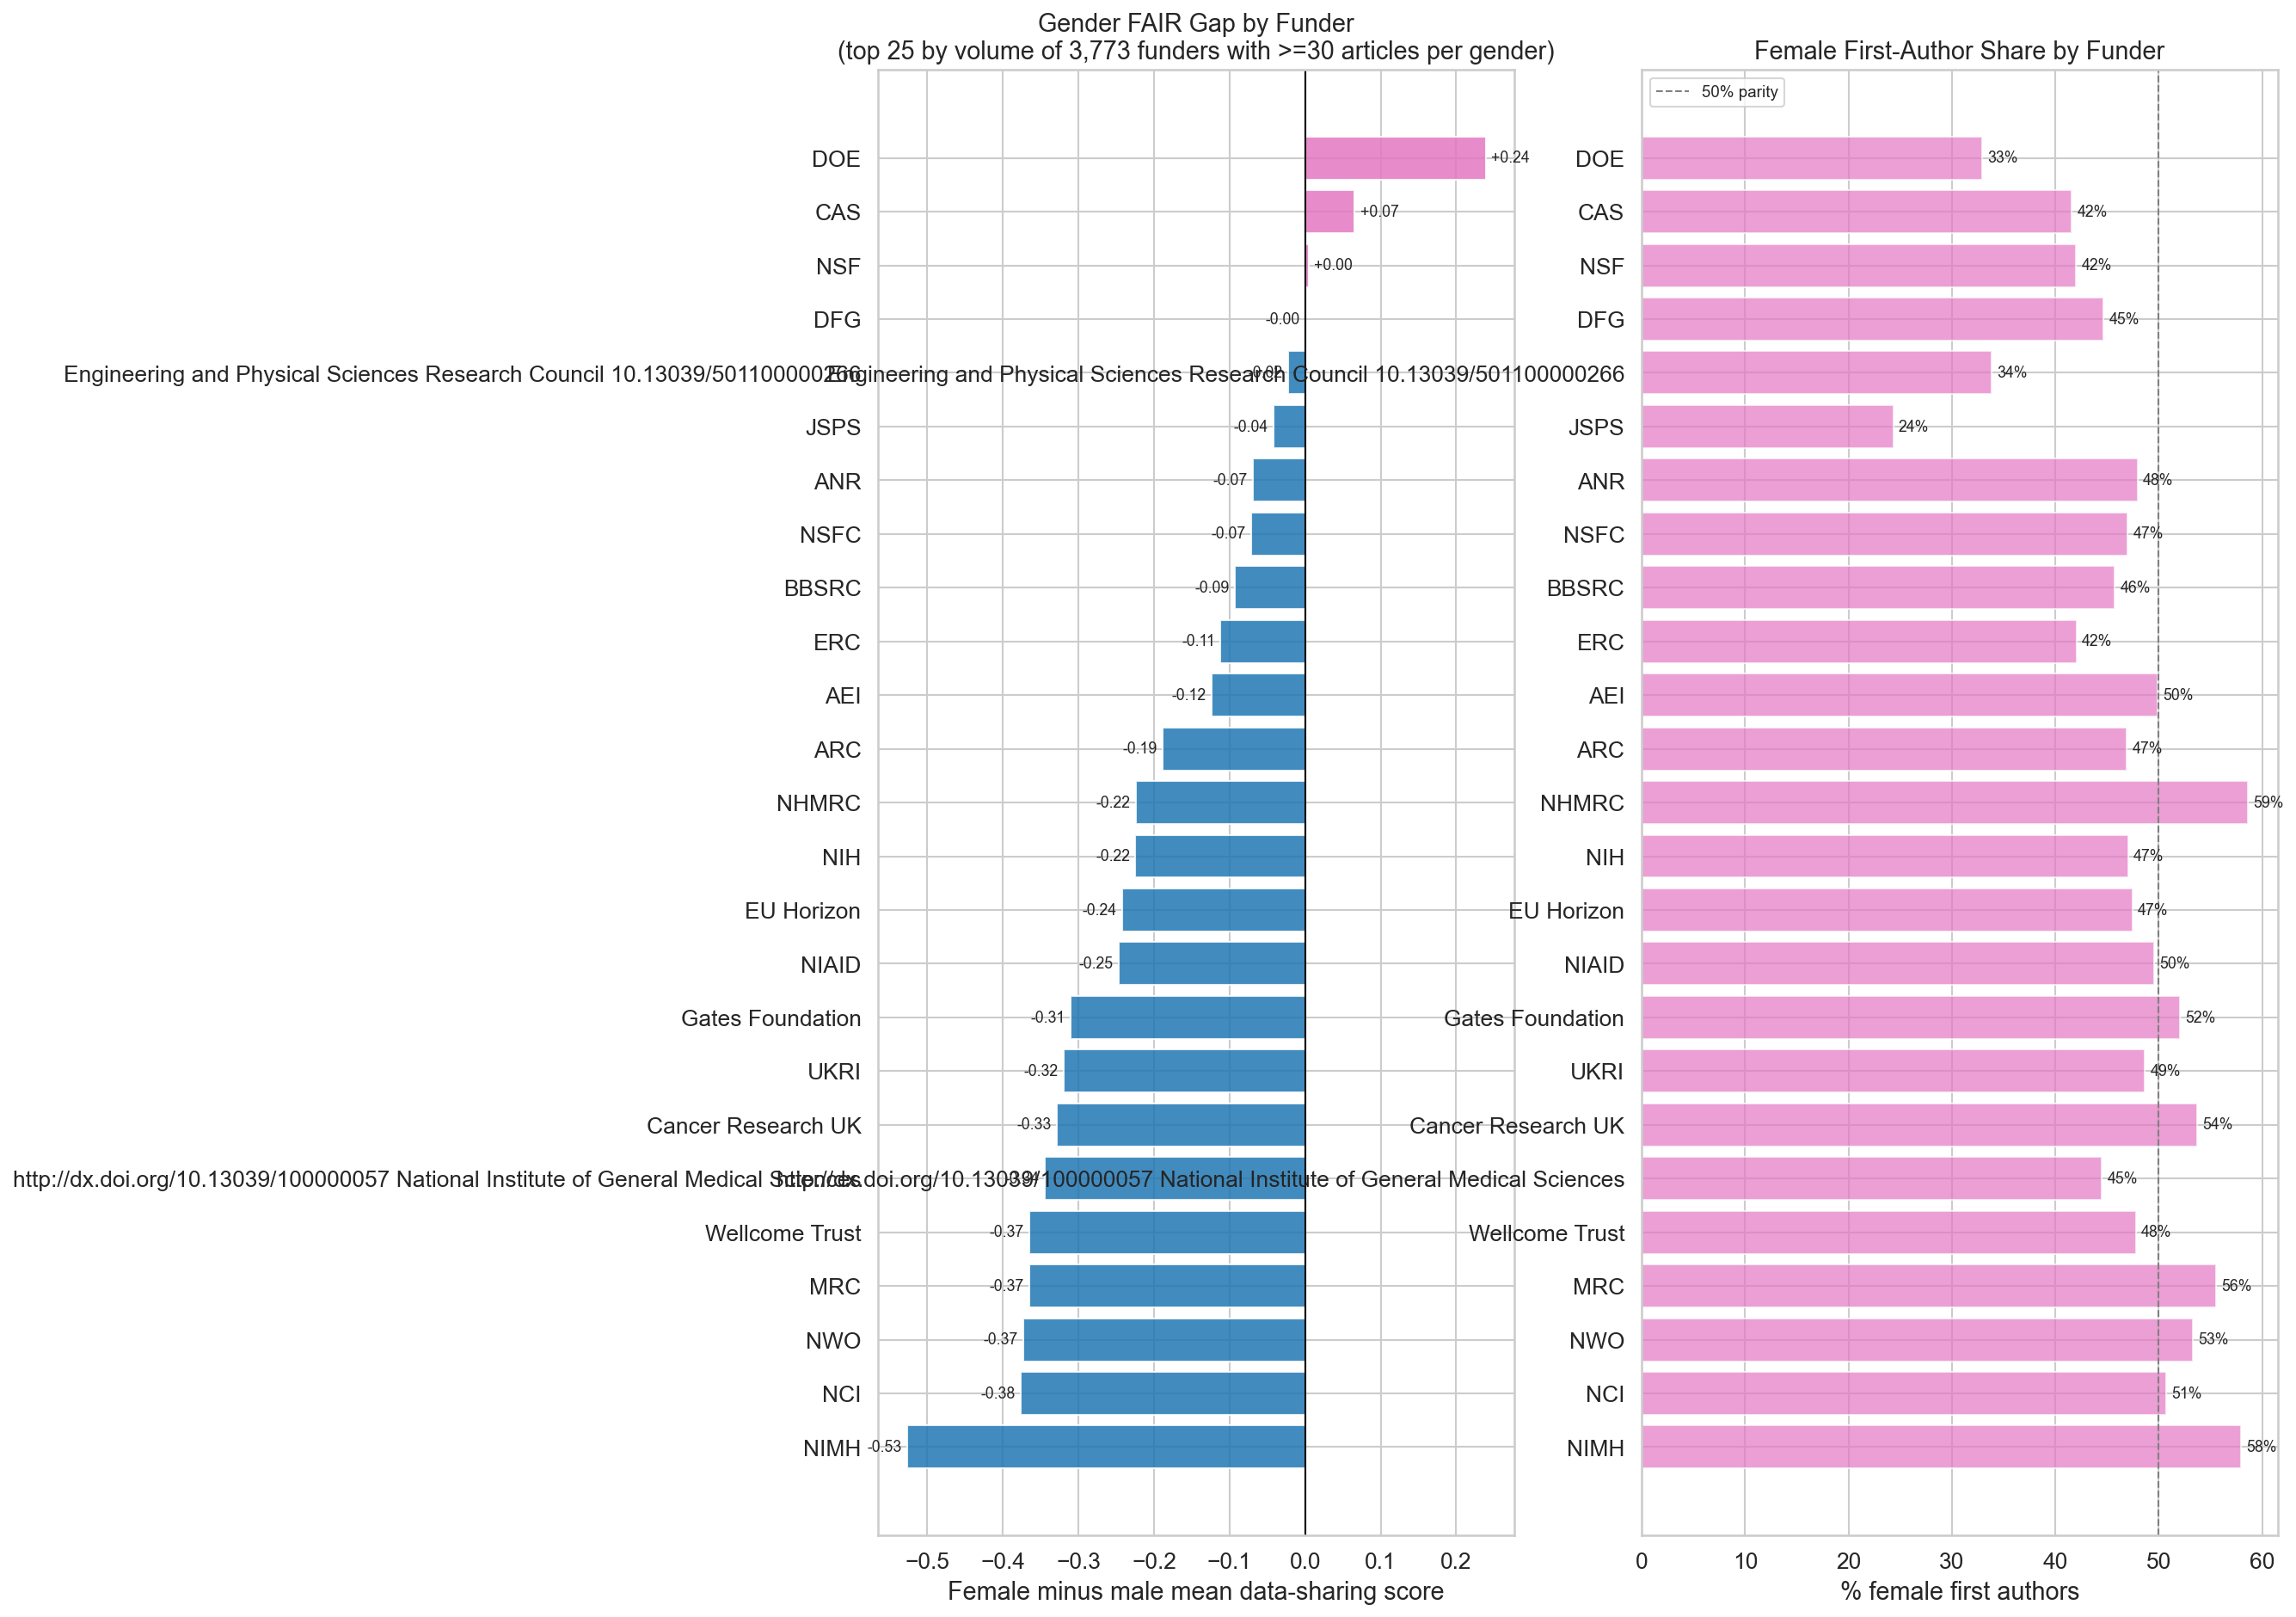

In [12]:
if not HAS_FUNDER:
    print('Skipped -- funder data not available in this database.')
else:
    df_fg = qdb("""
        SELECT af.article_id, af.funder_norm AS funder,
               dc.data_sharing_score, au.given_name,
               COALESCE(gg.gender, 'unknown') AS gender
        FROM article_funder  af
        JOIN article_author  aa  ON aa.article_id = af.article_id AND aa.author_position=1
        JOIN author          au  ON au.author_id  = aa.author_id
        JOIN article         a   ON a.article_id  = af.article_id
        JOIN das_category    dc  ON dc.article_id = af.article_id
        LEFT JOIN given_name_gender gg ON gg.given_name = au.given_name
        WHERE af.funder_norm != 'none' AND a.year BETWEEN 2011 AND 2025
    """)
    df_fg = df_fg[df_fg['gender'].isin(['female','male'])]

    fg = (df_fg.groupby(['funder','gender'])['data_sharing_score']
          .agg(n='count', mean='mean').reset_index())
    fg_piv = fg.pivot_table(index='funder',columns='gender',values='mean',aggfunc='mean')
    fg_n   = fg.pivot_table(index='funder',columns='gender',values='n',  aggfunc='sum')
    mask   = ((fg_n.get('female', pd.Series(0,index=fg_n.index)) >= 30) &
              (fg_n.get('male',   pd.Series(0,index=fg_n.index)) >= 30))
    fg_piv = fg_piv[mask].dropna()
    n_qualifying = len(fg_piv)
    fg_piv['n_total'] = (fg_n.get('female', pd.Series(0, index=fg_n.index)) +
                         fg_n.get('male',   pd.Series(0, index=fg_n.index))).reindex(fg_piv.index)
    # Cap to the 25 highest-volume qualifying funders (same convention as the
    # country/funder panels elsewhere) -- plotting all ~3,770 funders that
    # clear the >=30-per-gender bar produced a 240,000px-tall, 81MB,
    # unreadable PNG.
    fg_piv = fg_piv.nlargest(25, 'n_total')
    fg_piv['gap'] = fg_piv.get('female',0) - fg_piv.get('male',0)
    fg_piv = fg_piv.sort_values('gap')

    fg_share = (df_fg.groupby(['funder','gender'])
                .size().reset_index(name='n')
                .pivot_table(index='funder',columns='gender',values='n',aggfunc='sum')
                .fillna(0))
    fg_share['pct_f'] = (fg_share.get('female',0) /
                         fg_share[['female','male']].sum(axis=1) * 100)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W+1, max(5, len(fg_piv)*0.55+1)))

    ax = axes[0]
    clrs_f = ['#e377c2' if g>0 else '#1f77b4' for g in fg_piv['gap']]
    bars_f = ax.barh(fg_piv.index, fg_piv['gap'], color=clrs_f, alpha=0.85, edgecolor='white')
    ax.bar_label(bars_f, fmt='{:+.2f}', padding=3, fontsize=8.5)
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('Female minus male mean data-sharing score')
    ax.set_title(f'Gender FAIR Gap by Funder\n(top 25 by volume of {n_qualifying:,} funders with >=30 articles per gender)')

    ax = axes[1]
    pf_f = fg_share['pct_f'].reindex(fg_piv.index)
    ax.barh(pf_f.index, pf_f.values, color='#e377c2', alpha=0.7, edgecolor='white')
    ax.axvline(50, color='grey', lw=1, ls='--', label='50% parity')
    ax.bar_label(ax.containers[0], fmt='{:.0f}%', padding=3, fontsize=8.5)
    ax.set_xlabel('% female first authors'); ax.legend(fontsize=9)
    ax.set_title('Female First-Author Share by Funder')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_g07_funder.png", **SAVEFIG_KWARGS)
    plt.show()

---
## 7 . Gender x Open Access *(Stage 6)*

Female researchers have been reported to publish in OA venues at slightly
higher rates in some fields. If true here, OA status could partially
mediate the gender-FAIR relationship -- or the OA effect may be entirely
independent of gender.


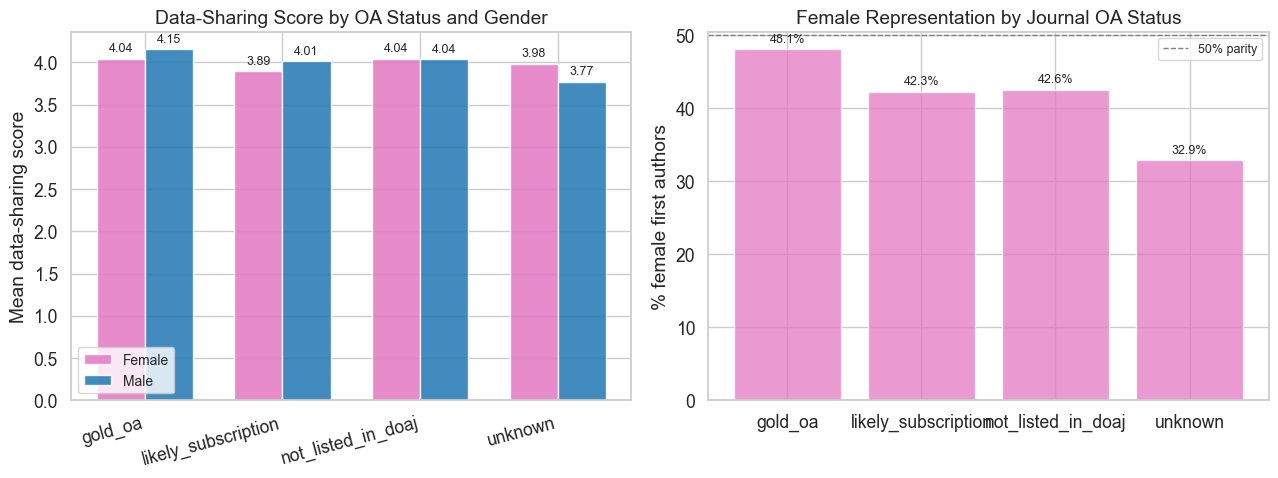

In [13]:
if not HAS_OA:
    print('Skipped -- OA status data not available in this database.')
else:
    df_og = qdb("""
        SELECT aa.article_id, jo.oa_status,
               dc.data_sharing_score, au.given_name,
               a.year AS year,
               COALESCE(gg.gender, 'unknown') AS gender
        FROM article_author  aa
        JOIN author          au  ON au.author_id  = aa.author_id
        JOIN article         a   ON a.article_id  = aa.article_id
        JOIN journal_oa      jo  ON jo.journal_id  = a.journal_id
        JOIN das_category    dc  ON dc.article_id  = aa.article_id
        LEFT JOIN given_name_gender gg ON gg.given_name = au.given_name
        WHERE aa.author_position=1 AND a.year BETWEEN 2011 AND 2025
    """)
    df_og = df_og[df_og['gender'].isin(['female','male'])]

    og_stats = (df_og.groupby(['oa_status','gender'])['data_sharing_score']
                .agg(n='count', mean='mean', std='std').reset_index())
    oa_share = (df_og.groupby(['oa_status','gender'])
                .size().reset_index(name='n')
                .pivot_table(index='oa_status',columns='gender',values='n',aggfunc='sum')
                .fillna(0))
    oa_share['pct_f'] = (oa_share.get('female',0) /
                         oa_share[['female','male']].sum(axis=1) * 100)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

    ax = axes[0]
    oa_types = og_stats['oa_status'].unique()
    x_o = np.arange(len(oa_types)); w_o = 0.35
    for j, (g, c) in enumerate([('female','#e377c2'),('male','#1f77b4')]):
        mn = [og_stats[(og_stats['oa_status']==o)&(og_stats['gender']==g)]['mean'].values
              for o in oa_types]
        mn = [v[0] if len(v) else np.nan for v in mn]
        b  = ax.bar(x_o+(j-0.5)*w_o, mn, w_o, label=g.capitalize(),
                    color=c, alpha=0.85, edgecolor='white')
        ax.bar_label(b, fmt='{:.2f}', padding=3, fontsize=9)
    ax.set_xticks(x_o); ax.set_xticklabels(oa_types, rotation=15, ha='right')
    ax.set_ylabel('Mean data-sharing score'); ax.legend(fontsize=10)
    ax.set_title('Data-Sharing Score by OA Status and Gender')

    ax = axes[1]
    ax.bar(oa_share.index.astype(str), oa_share['pct_f'],
           color='#e377c2', alpha=0.75, edgecolor='white')
    ax.bar_label(ax.containers[0], fmt='{:.1f}%', padding=3, fontsize=9)
    ax.axhline(50, color='grey', lw=1, ls='--', label='50% parity')
    ax.set_ylabel('% female first authors')
    ax.set_title('Female Representation by Journal OA Status')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_g08_oa.png", **SAVEFIG_KWARGS)
    plt.show()

---
## 8 . Productivity Trajectories by Gender

Prolific authors control more lab infrastructure and are more likely
to have established data-deposition routines. If female researchers
are on average earlier-career (fewer papers), productivity confounding
could inflate or deflate the observed FAIR gap. We test this by
computing per-author scores stratified by output volume.

**Original idea**: we also plot each author's pre-to-post improvement
as a scatter, coloured by gender, to see whether individual trajectories
cluster by gender or by productivity tier.


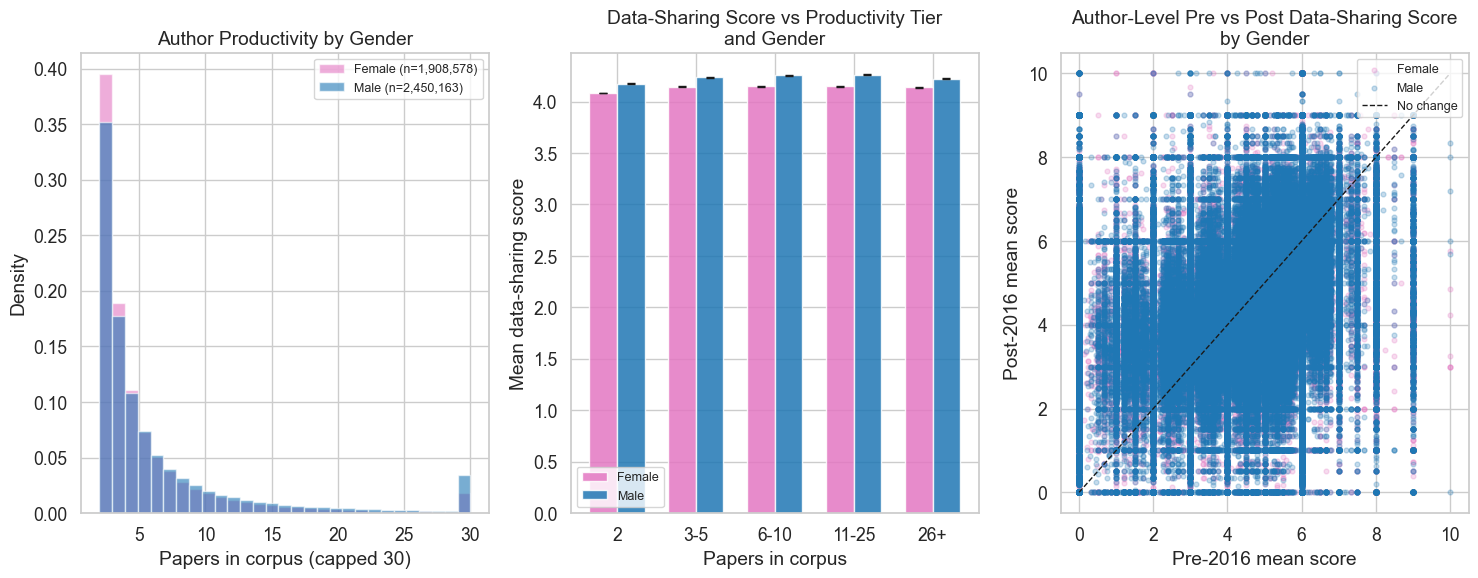

Median papers -- Female: 3.0  Male: 3.0  p=0.000e+00


In [14]:
if 'author_productivity' not in tables:
    print('Skipped -- author_productivity not precomputed. Run '
          '`python pipeline/compute_gender_extras.py --db <path>` first.')
else:
    # Author-level productivity aggregates (n_papers, avg/pre/post score,
    # first_rate) are precomputed offline in pipeline/compute_gender_extras.py
    # via a single server-side GROUP BY over article_author/article/
    # das_category only -- no author or given_name_gender join inside that
    # GROUP BY at all. The original in-notebook version of this query joined
    # gender into the same GROUP BY that had to scan every author position on
    # every article (~47.9M rows), which is what was hitting DeadKernelError
    # even after chunking elsewhere in this notebook fixed similar issues
    # (confirmed via EXPLAIN QUERY PLAN and direct timing against the live
    # database -- see that script's module docstring for the full root-cause
    # analysis). Gender is attached back here afterwards as a cheap,
    # purely in-memory pandas merge against the small author/
    # given_name_gender tables (13.4M and 2.15M rows respectively, vs the
    # 47.9M-row article_author table the heavy aggregation itself touches).
    _prod_raw = qdb("SELECT * FROM author_productivity")
    _author_names = qdb("SELECT author_id, given_name FROM author")
    _name_gender_map = dict(qdb(
        "SELECT given_name, gender FROM given_name_gender"
    ).itertuples(index=False, name=None))

    df_prod = _prod_raw.merge(_author_names, on='author_id', how='left')
    df_prod['gender'] = df_prod['given_name'].map(_name_gender_map).fillna('unknown')
    del _prod_raw, _author_names, _name_gender_map

    df_prod = df_prod[df_prod['gender'].isin(['female','male'])].copy()
    df_prod['delta'] = df_prod['post_score'] - df_prod['pre_score']
    df_prod['tier']  = pd.cut(df_prod['n_papers'], bins=[1,3,5,10,25,9999],
                              labels=['2','3-5','6-10','11-25','26+'])

    tier_g = (df_prod.groupby(['tier','gender'])['avg_score']
              .agg(n='count', mean='mean', std='std').reset_index())
    tier_g['ci95'] = 1.96 * tier_g['std'] / np.sqrt(tier_g['n'])

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W+2, FIG_H+1))

    # Productivity histogram
    ax = axes[0]
    for g, c in [('female','#e377c2'),('male','#1f77b4')]:
        d = df_prod[df_prod['gender']==g]['n_papers']
        ax.hist(np.clip(d,1,30), bins=29, alpha=0.6, color=c, edgecolor='white',
                label=f'{g.capitalize()} (n={len(d):,})', density=True)
    ax.set_xlabel('Papers in corpus (capped 30)'); ax.set_ylabel('Density')
    ax.set_title('Author Productivity by Gender')
    ax.legend(fontsize=9)

    # data-sharing score by productivity tier x gender
    ax = axes[1]
    tiers = ['2','3-5','6-10','11-25','26+']
    x_t = np.arange(5); w_t = 0.35
    for j, (g, c) in enumerate([('female','#e377c2'),('male','#1f77b4')]):
        mn = [tier_g[(tier_g['gender']==g)&(tier_g['tier']==t)]['mean'].values for t in tiers]
        er = [tier_g[(tier_g['gender']==g)&(tier_g['tier']==t)]['ci95'].values for t in tiers]
        mn = [v[0] if len(v) else np.nan for v in mn]
        er = [v[0] if len(v) else 0      for v in er]
        b  = ax.bar(x_t+(j-0.5)*w_t, mn, w_t, label=g.capitalize(),
                    color=c, alpha=0.85, edgecolor='white', yerr=er, capsize=3)
    ax.set_xticks(x_t); ax.set_xticklabels(tiers)
    ax.set_xlabel('Papers in corpus'); ax.set_ylabel('Mean data-sharing score')
    ax.set_title('Data-Sharing Score vs Productivity Tier\nand Gender')
    ax.legend(fontsize=9)

    # Pre vs post scatter coloured by gender
    ax = axes[2]
    for g, c in [('female','#e377c2'),('male','#1f77b4')]:
        d = df_prod[df_prod['gender']==g].dropna(subset=['pre_score','post_score'])
        ax.scatter(d['pre_score'], d['post_score'], alpha=0.25, s=12,
                   color=c, label=g.capitalize(), rasterized=True)
    ax.plot([0,10],[0,10],'k--', lw=1, label='No change')
    ax.set_xlabel('Pre-2016 mean score'); ax.set_ylabel('Post-2016 mean score')
    ax.set_title('Author-Level Pre vs Post Data-Sharing Score\nby Gender')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_g09_productivity.png", **SAVEFIG_KWARGS)
    plt.show()

    fp = df_prod[df_prod['gender']=='female']['n_papers']
    mp = df_prod[df_prod['gender']=='male']['n_papers']
    u_p, p_p = stats.mannwhitneyu(fp, mp, alternative='two-sided')
    print(f'Median papers -- Female: {fp.median():.1f}  Male: {mp.median():.1f}  p={p_p:.3e}')


---
## 9 . Solo-Country vs International Collaboration x Gender

**Original idea**: internationally collaborative papers may have higher
data-sharing rates because they are subject to multiple national mandates
simultaneously. Are female first authors on international papers more
likely to deposit data than their domestic counterparts? And is the gender
composition of internationally collaborative papers different from single-
country papers?


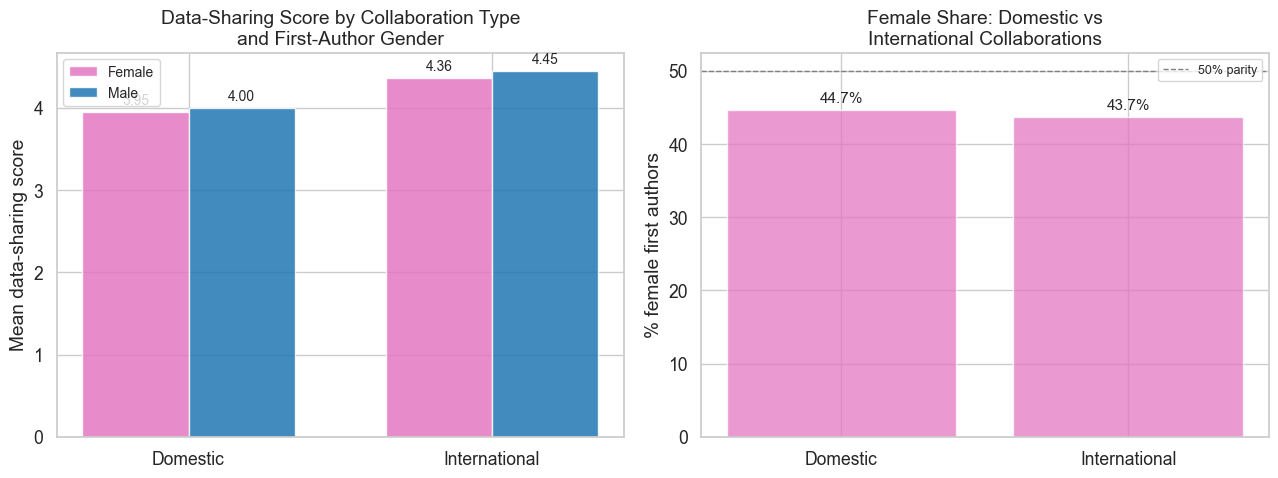

       collab gender       n  mean
     Domestic female 1806053 3.948
     Domestic   male 2237766 3.997
International female  337483 4.361
International   male  434645 4.448


In [15]:
# International-collaboration status (>=2 distinct co-author countries per
# article) and per-article country counts are precomputed offline in
# pipeline/compute_gender_extras.py as `article_country_count`, using the
# same compiled-alternation-regex country extractor as
# notebooks/11_geographical.ipynb Section 5.0 (that notebook already solved
# the exact "loop over ~250 country-name regexes per row" slowdown this
# cell used to repeat) -- applied once per DISTINCT affiliation string
# (11.3M; ~80k/s measured) rather than once per author-affiliation row
# (36.5M, with duplicates), and without ever joining author/das_category/
# given_name_gender into that pass. This cell now only needs a cheap merge
# of that small, already-computed table onto df_first (already loaded in
# Section 1), instead of re-running the full multi-table join across every
# author position on every article, which is what was hitting
# DeadKernelError even after a first round of fixes elsewhere in this
# notebook (confirmed via EXPLAIN QUERY PLAN and direct timing against the
# live database -- see that script's module docstring for the full
# root-cause analysis).
if 'article_country_count' not in tables:
    print('Skipped -- article_country_count not precomputed. Run '
          '`python pipeline/compute_gender_extras.py --db <path>` first.')
else:
    n_countries = qdb("SELECT article_id, n_countries FROM article_country_count")

    df_fc = df_first.merge(n_countries, on='article_id', how='left')
    df_fc['is_intl'] = df_fc['n_countries'].fillna(1) >= 2
    df_fc = df_fc[df_fc['gender'].isin(['female','male'])]

    cg_stats = (df_fc.groupby(['is_intl','gender'])['data_sharing_score']
                .agg(n='count', mean='mean').reset_index())
    cg_stats['collab'] = cg_stats['is_intl'].map({True:'International',False:'Domestic'})

    cg_share = (df_fc.groupby(['is_intl','gender'])
                .size().reset_index(name='n')
                .pivot_table(index='is_intl',columns='gender',values='n',aggfunc='sum')
                .fillna(0))
    cg_share['pct_f'] = (cg_share.get('female',0) /
                         cg_share[['female','male']].sum(axis=1) * 100)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

    ax = axes[0]
    types = ['Domestic','International']
    x_c = np.arange(2); w_c = 0.35
    for j, (g, c) in enumerate([('female','#e377c2'),('male','#1f77b4')]):
        mn = [cg_stats[(cg_stats['collab']==t)&(cg_stats['gender']==g)]['mean'].values
              for t in types]
        mn = [v[0] if len(v) else np.nan for v in mn]
        b  = ax.bar(x_c+(j-0.5)*w_c, mn, w_c, label=g.capitalize(),
                    color=c, alpha=0.85, edgecolor='white')
        ax.bar_label(b, fmt='{:.2f}', padding=3, fontsize=10)
    ax.set_xticks(x_c); ax.set_xticklabels(types)
    ax.set_ylabel('Mean data-sharing score'); ax.legend(fontsize=10)
    ax.set_title('Data-Sharing Score by Collaboration Type\nand First-Author Gender')

    ax = axes[1]
    cg_share.index = cg_share.index.map({True:'International',False:'Domestic'})
    ax.bar(cg_share.index.astype(str), cg_share['pct_f'],
           color='#e377c2', alpha=0.75, edgecolor='white')
    ax.bar_label(ax.containers[0], fmt='{:.1f}%', padding=3, fontsize=11)
    ax.axhline(50, color='grey', lw=1, ls='--', label='50% parity')
    ax.set_ylabel('% female first authors')
    ax.set_title('Female Share: Domestic vs\nInternational Collaborations')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_g10_collab.png", **SAVEFIG_KWARGS)
    plt.show()
    print(cg_stats[['collab','gender','n','mean']].round(3).to_string(index=False))


---
## 10 . Name Inference Quality Audit

Before drawing conclusions it is important to characterise how accurate
and unbiased the name-based inference is. Key concerns:
- Initials-only authors are systematically unresolvable
- East Asian and African names have lower library coverage
- Ambiguity rate may vary by year or discipline, introducing differential bias


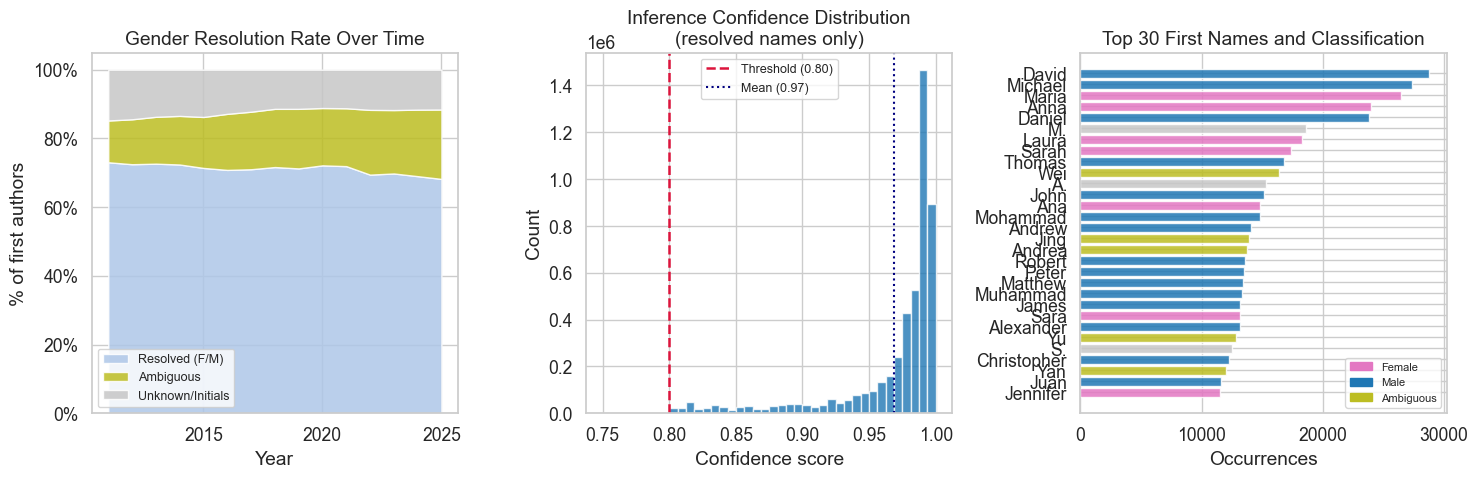

Overall resolution rate : 71.2%
Mean confidence (F+M)   : 0.968
Unresolvable (unknown)  : 12.5%
Ambiguous               : 16.4%


In [16]:
# Resolution rate breakdown by year
res_yr = (df_first.groupby(['year','gender'])
          .size().reset_index(name='n'))
res_piv = (res_yr.pivot_table(index='year',columns='gender',values='n',aggfunc='sum').fillna(0))
for g in ['female','male','ambiguous','unknown']:
    if g not in res_piv.columns: res_piv[g] = 0
res_piv['total'] = res_piv.sum(axis=1)
res_piv['pct_resolved']  = (res_piv['female']+res_piv['male'])  / res_piv['total'] * 100
res_piv['pct_ambiguous'] =  res_piv['ambiguous'] / res_piv['total'] * 100
res_piv['pct_unknown']   =  res_piv['unknown']   / res_piv['total'] * 100

# Confidence distribution for resolved names
conf_vals = df_first[df_first['gender'].isin(['female','male'])]['g_conf'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(FIG_W+2, FIG_H))

# Stacked area
ax = axes[0]
ax.stackplot(res_piv.index,
             res_piv['pct_resolved'],
             res_piv['pct_ambiguous'],
             res_piv['pct_unknown'],
             labels=['Resolved (F/M)','Ambiguous','Unknown/Initials'],
             colors=['#aec7e8','#bcbd22','#c7c7c7'], alpha=0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of first authors')
ax.set_title('Gender Resolution Rate Over Time')
ax.legend(loc='lower left', fontsize=9)

# Confidence histogram
ax = axes[1]
ax.hist(conf_vals, bins=40, color=PALETTE[0], alpha=0.8, edgecolor='white')
ax.axvline(0.80, color='crimson', lw=1.8, ls='--', label='Threshold (0.80)')
ax.axvline(conf_vals.mean(), color='navy', lw=1.5, ls=':',
           label=f'Mean ({conf_vals.mean():.2f})')
ax.set_xlabel('Confidence score'); ax.set_ylabel('Count')
ax.set_title('Inference Confidence Distribution\n(resolved names only)')
ax.legend(fontsize=9)

# Top 30 names audit -- reuses df_first's already-resolved gender/g_conf
# columns (one row per token already has a single consistent label/confidence
# since every full given_name sharing a leading token resolves the same way;
# see pipeline/compute_gender.py). No live model call needed here.
top_names = (df_first.dropna(subset=['given_name'])
             .assign(tok=df_first['given_name'].str.split().str[0].str.capitalize())
             .groupby('tok')
             .agg(n=('tok', 'size'),
                  label=('gender', lambda s: s.mode().iat[0] if not s.mode().empty else 'unknown'),
                  conf=('g_conf', 'mean'))
             .reset_index()
             .nlargest(30, 'n'))

ax = axes[2]
clrs_n = [G_PAL.get(g,'#c7c7c7') for g in top_names['label']]
ax.barh(top_names['tok'][::-1], top_names['n'][::-1],
        color=clrs_n[::-1], alpha=0.85, edgecolor='white')
ax.set_xlabel('Occurrences')
ax.set_title('Top 30 First Names and Classification')
handles = [plt.Rectangle((0,0),1,1,color=G_PAL[g]) for g in ['female','male','ambiguous']]
ax.legend(handles, ['Female','Male','Ambiguous'], fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_g11_audit.png", **SAVEFIG_KWARGS)
plt.show()

print(f'Overall resolution rate : {res_piv["pct_resolved"].mean():.1f}%')
print(f'Mean confidence (F+M)   : {conf_vals.mean():.3f}')
print(f'Unresolvable (unknown)  : {res_piv["pct_unknown"].mean():.1f}%')
print(f'Ambiguous               : {res_piv["pct_ambiguous"].mean():.1f}%')

---
## 11 . Statistical Summary Dashboard + Exports

Consolidated Mann-Whitney results for every binary gender comparison
in this notebook, with effect sizes and significance flags.


In [ ]:
# "All authors" comparison needs every article_author row (~47.9M, all author
# positions) -- unlike everything else in this notebook, which only ever
# needed df_first. Streaming the read in bounded chunks (still done below)
# fixed the Python-memory side of this, but it was still hitting
# DeadKernelError afterwards: the SQL-side LEFT JOIN against
# given_name_gender was keyed on the TEXT column given_name, which forces a
# B-tree text-key lookup for every one of ~47.9M rows -- far more expensive
# per row than the integer-keyed joins against article/das_category/author,
# and the direct cause of the continued kernel deaths (confirmed via
# EXPLAIN QUERY PLAN and timing against the live database, not guessed; see
# pipeline/compute_gender_extras.py's module docstring for the full
# root-cause analysis of the sibling issues this notebook was hitting).
# Fixed by removing that join from SQL entirely: given_name_gender has only
# ~2.15M rows (one per distinct given name), so it is loaded once, in full,
# into a plain Python dict, and gender is resolved afterwards with a single
# vectorized pandas .map() call per chunk instead of a per-row SQL join.
_name_gender_map = dict(qdb(
    "SELECT given_name, gender FROM given_name_gender"
).itertuples(index=False, name=None))

CHUNK = 500_000
_f_chunks, _m_chunks = [], []
_all_pos_query = """
    SELECT au.given_name, dc.data_sharing_score
    FROM article_author  aa
    JOIN article          a   ON a.article_id  = aa.article_id
    JOIN das_category     dc  ON dc.article_id = aa.article_id
    JOIN author            au  ON au.author_id  = aa.author_id
    WHERE a.year BETWEEN 2011 AND 2025
"""
for _chunk in pd.read_sql_query(_all_pos_query, con, chunksize=CHUNK):
    _gender = _chunk['given_name'].map(_name_gender_map).fillna('unknown')
    _f_chunks.append(_chunk.loc[_gender == 'female', 'data_sharing_score'].to_numpy())
    _m_chunks.append(_chunk.loc[_gender == 'male',   'data_sharing_score'].to_numpy())
f_all = np.concatenate(_f_chunks)
m_all = np.concatenate(_m_chunks)
del _f_chunks, _m_chunks, _name_gender_map
print(f'All-author rows classified: {len(f_all):,} female, {len(m_all):,} male')

summary_rows = []

def mw_row(label, series_a, series_b, note=''):
    if len(series_a) < 5 or len(series_b) < 5:
        return {'Comparison':label,'F mean':'--','M mean':'--',
                'Gap F-M':'--','p-value':'--','Effect r':'--','Note':note}
    u, p = stats.mannwhitneyu(series_a, series_b, alternative='two-sided')
    # See cell above: u/(n1*n2) is CLES, not rank-biserial r. Convert properly.
    cles = u / (len(series_a)*len(series_b))
    r_e  = 2 * cles - 1
    # np.mean() works for both pandas Series (first-author calls below) and
    # the plain numpy arrays used for the "All authors" row above.
    return {
        'Comparison': label,
        'F mean':  f'{np.mean(series_a):.3f}',
        'M mean':  f'{np.mean(series_b):.3f}',
        'Gap F-M': f'{np.mean(series_a)-np.mean(series_b):+.3f}',
        'p-value': f'{p:.2e}',
        'Effect r':f'{r_e:.4f}',
        'Note': note,
    }

df_fm_fa = df_fm

summary_rows.append(mw_row('All authors -- data-sharing score', f_all, m_all))
del f_all, m_all

summary_rows.append(mw_row(
    'First authors -- data-sharing score',
    df_fm_fa[df_fm_fa['gender']=='female']['data_sharing_score'],
    df_fm_fa[df_fm_fa['gender']=='male'  ]['data_sharing_score']))

summary_rows.append(mw_row(
    'First authors -- pre-2016',
    f_pre, m_pre, note='2011-2015'))
summary_rows.append(mw_row(
    'First authors -- post-2016',
    f_post, m_post, note='2017-2025'))

df_sum = pd.DataFrame(summary_rows)
print('='*95)
print('GENDER x FAIR -- STATISTICAL SUMMARY')
print('='*95)
print(df_sum.to_string(index=False))
print('\nEffect r: < 0.1 negligible | 0.1-0.3 small | 0.3-0.5 medium | >0.5 large')

In [18]:
# Key findings box
pre_f  = f_pre.mean();  pre_m  = m_pre.mean()
post_f = f_post.mean(); post_m = m_post.mean()
ov_f   = df_fm[df_fm['gender']=='female']['data_sharing_score'].mean()
ov_m   = df_fm[df_fm['gender']=='male'  ]['data_sharing_score'].mean()
n_f    = (df_first['gender']=='female').sum()
n_m    = (df_first['gender']=='male').sum()
n_unk  = df_first['gender'].isin(['unknown','ambiguous']).sum()

print(f'''
+-----------------------------------------------------------------+
|       GENDER & FAIR -- KEY FINDINGS SUMMARY                    |
+-----------------------------------------------------------------+
|  First authors classified:                                      |
|    Female     : {n_f:>8,}                                      |
|    Male       : {n_m:>8,}                                      |
|    Unresolved : {n_unk:>8,}                                      |
|                                                                 |
|  Overall FAIR gap (F - M)  : {ov_f - ov_m:+.3f}                        |
|  Pre-2016 gap  (F - M)     : {pre_f  - pre_m:+.3f}                        |
|  Post-2016 gap (F - M)     : {post_f - post_m:+.3f}                        |
|  Gap change DiD            : {(post_f-post_m)-(pre_f-pre_m):+.3f}                        |
+-----------------------------------------------------------------+
''')



+-----------------------------------------------------------------+
|       GENDER & FAIR -- KEY FINDINGS SUMMARY                    |
+-----------------------------------------------------------------+
|  First authors classified:                                      |
|    Female     : 2,143,536                                      |
|    Male       : 2,672,411                                      |
|    Unresolved : 2,014,395                                      |
|                                                                 |
|  Overall FAIR gap (F - M)  : -0.057                        |
|  Pre-2016 gap  (F - M)     : +0.116                        |
|  Post-2016 gap (F - M)     : -0.076                        |
|  Gap change DiD            : -0.192                        |
+-----------------------------------------------------------------+



In [19]:
# Export
export_dir = Path('../results/fair_gender_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'gender_composition_by_year.csv': comp_piv.reset_index(),
    'fair_score_by_gender_year.csv':  score_yr,
    'das_category_by_gender.csv':     piv_pct.reset_index(),
    'period_gender_stats.csv':        period_stats,
    'author_gender_scores.csv':       df_prod[['author_id','gender','n_papers',
                                               'avg_score','pre_score','post_score',
                                               'delta','first_rate']],
    'summary_statistics.csv':         df_sum,
}
for fname, df_e in exports.items():
    df_e.to_csv(export_dir / fname, index=False)
    print(f'  Saved {fname}  ({len(df_e):,} rows)')

con.close()
print('\nDone. Database connection closed.')


  Saved gender_composition_by_year.csv  (15 rows)
  Saved fair_score_by_gender_year.csv  (30 rows)
  Saved das_category_by_gender.csv  (2 rows)
  Saved period_gender_stats.csv  (4 rows)


  Saved author_gender_scores.csv  (4,358,741 rows)
  Saved summary_statistics.csv  (4 rows)

Done. Database connection closed.
